# Task 1 · Iris Flower Classification

**Track:** Data Science

**Author:** Robin Kumar

**Objective:** Train a machine learning model that predicts the species of an iris flower (Setosa, Versicolor or Virginica) from its sepal and petal measurements.

**Steps in this notebook**
1. Import libraries
2. Load the dataset
3. Exploratory Data Analysis (EDA)
4. Visualisations
5. Feature selection discussion
6. Train / test split
7. Feature scaling
8. Train the models
9. Evaluate the models
10. Best-performing model
11. Conclusion

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

# One fixed colour for each species, used in all the plots
species_colors = {"setosa": "#2a78d6", "versicolor": "#eb6834", "virginica": "#1baf7a"}

## 2. Load the dataset

The Iris dataset is already included in scikit-learn, so it does not need to be downloaded.

In [2]:
iris = load_iris()

# Put the data into a pandas DataFrame so it is easy to explore
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = iris.target                      # 0, 1, 2
df["species"] = df["species"].map({0: "setosa", 1: "versicolor", 2: "virginica"})

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory Data Analysis (EDA)

### Shape and data types

In [3]:
print("Shape of the dataset:", df.shape)
print()
print(df.dtypes)

Shape of the dataset: (150, 5)

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                  str
dtype: object


### Null value check

In [4]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

### Number of flowers in each species

In [5]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

### Descriptive statistics

In [6]:
df.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [7]:
# Average measurement of each species
df.groupby("species").mean().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


**Observations**

- The dataset has 150 rows and 5 columns: 4 numeric features (in cm) and the species.
- There are no null values, so no cleaning is needed.
- Each species has exactly 50 flowers, so the dataset is balanced.
- The average petal length and petal width are very different for the three species. The sepal measurements are much closer to each other.

## 4. Visualisations

### Pairplot

The pairplot shows every pair of features as a scatter plot, with a different colour for each species.

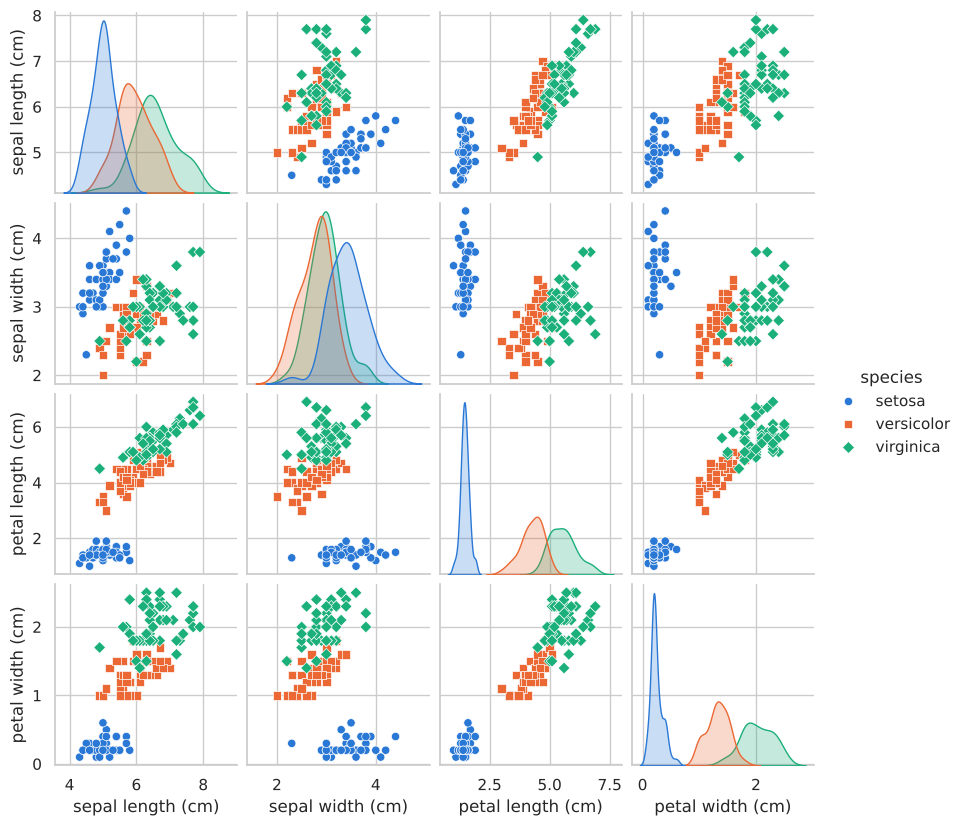

In [8]:
sns.pairplot(df, hue="species", palette=species_colors, markers=["o", "s", "D"], height=2.1)
plt.show()

### Box plots for each feature

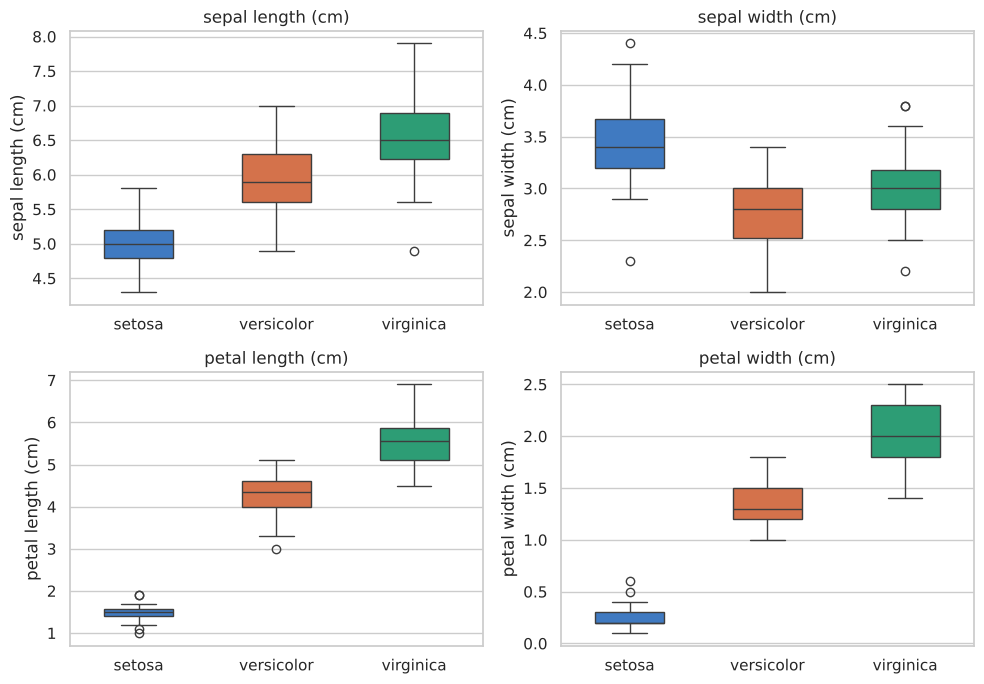

In [9]:
features = iris.feature_names

plt.figure(figsize=(10, 7))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(data=df, x="species", y=features[i], hue="species", palette=species_colors, legend=False, width=0.5)
    plt.title(features[i])
    plt.xlabel("")
plt.tight_layout()
plt.show()

### Correlation heatmap

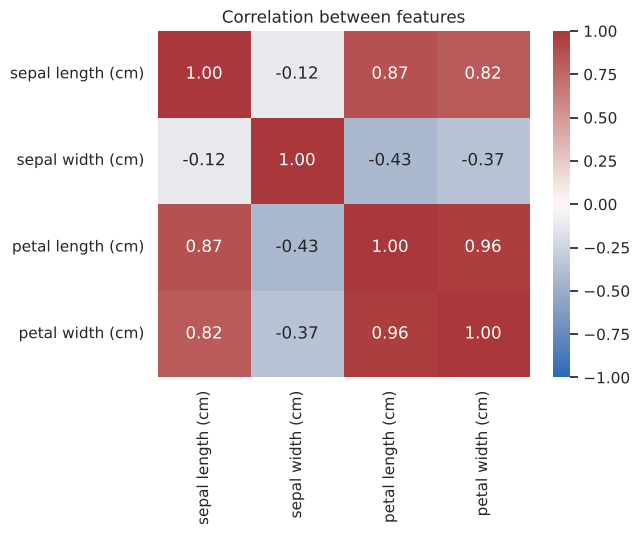

In [10]:
correlation = df[features].corr()

plt.figure(figsize=(6, 4.5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1)
plt.title("Correlation between features")
plt.show()

**Observations from the plots**

- Setosa is clearly separated from the other two species, especially on petal length and petal width.
- Versicolor and Virginica overlap a little, so most mistakes are expected between these two.
- In the box plots, the petal features have almost no overlap between species. Sepal width overlaps the most.
- Petal length and petal width are strongly correlated (0.96).

## 5. Feature selection discussion

**Which features are most discriminative?**

| Feature | Setosa (mean) | Versicolor (mean) | Virginica (mean) | How well it separates the species |
|---|---|---|---|---|
| Petal length | 1.46 | 4.26 | 5.55 | Very well |
| Petal width | 0.25 | 1.33 | 2.03 | Very well |
| Sepal length | 5.01 | 5.94 | 6.59 | Partly |
| Sepal width | 3.43 | 2.77 | 2.97 | Poorly |

- **Petal length and petal width are the most discriminative features.** Their values are far apart for the three species and the box plots barely overlap.
- Sepal length helps a little. Sepal width is the weakest feature because all three species have similar values.
- The dataset has only 4 features, so all of them are kept for training. Section 9 checks this again using the feature importance of the Decision Tree.

## 6. Train / test split

80% of the data is used for training and 20% for testing. `stratify=y` keeps the same number of flowers of each species in both parts.

In [11]:
X = df[features]      # input features
y = df["species"]     # target label

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (120, 4)
Testing set : (30, 4)


## 7. Feature scaling

Models like KNN use distance, so the features should be on the same scale. `StandardScaler` changes each feature to have mean 0 and standard deviation 1. The scaler is fitted only on the training data and then applied to the test data.

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 8. Train the models

Three classifiers are trained on the same training data:

- **Logistic Regression**: draws straight-line boundaries between the classes.
- **K-Nearest Neighbours (KNN)**: looks at the 5 nearest training flowers and takes the majority species.
- **Decision Tree**: learns simple if/else rules on the features.

In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
}

for name in models:
    models[name].fit(X_train_scaled, y_train)
    print(name, "trained")

Logistic Regression trained
KNN trained
Decision Tree trained


## 9. Evaluate the models

Each model is evaluated on the test set using:

- **Accuracy**: percentage of correct predictions.
- **Confusion matrix**: rows are the actual species, columns are the predicted species.
- **Classification report**: precision, recall and F1-score for each species.

In [14]:
labels = ["setosa", "versicolor", "virginica"]
test_accuracy = {}
predictions = {}

for name in models:
    y_pred = models[name].predict(X_test_scaled)
    predictions[name] = y_pred
    test_accuracy[name] = accuracy_score(y_test, y_pred)

    print("=" * 55)
    print(name)
    print("=" * 55)
    print("Accuracy:", round(test_accuracy[name], 4))
    print()
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred, labels=labels))
    print()
    print("Classification report:")
    print(classification_report(y_test, y_pred))

Logistic Regression
Accuracy: 0.9333

Confusion matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

KNN
Accuracy: 0.9333

Confusion matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Decision Tree
Accura

### Confusion matrices as heatmaps

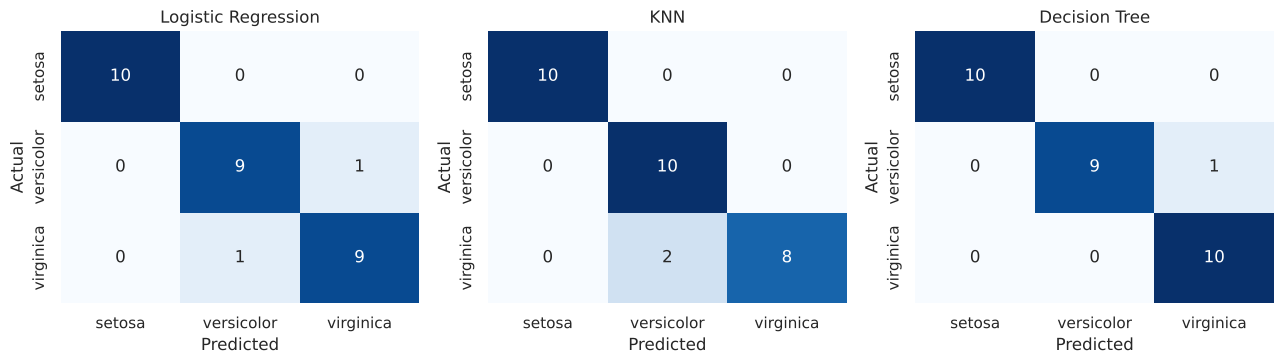

In [15]:
plt.figure(figsize=(13, 3.8))
i = 1
for name in models:
    cm = confusion_matrix(y_test, predictions[name], labels=labels)
    plt.subplot(1, 3, i)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=labels, yticklabels=labels)
    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    i = i + 1
plt.tight_layout()
plt.show()

### Comparing the models

Along with the test accuracy, the table also shows the **train accuracy**, which is the accuracy on the training data. If it is much higher than the test accuracy, the model is overfitting.

In [16]:
rows = []
for name in models:
    train_acc = models[name].score(X_train_scaled, y_train)
    correct = (predictions[name] == y_test).sum()        # number of correct predictions out of 30
    rows.append([name, train_acc, test_accuracy[name], correct])

results = pd.DataFrame(rows, columns=["Model", "Train accuracy", "Test accuracy", "Correct (out of 30)"])
# Sort by test accuracy (best model first)
results = results.sort_values("Test accuracy", ascending=False).reset_index(drop=True)
results.round(4)

,Model,Train accuracy,Test accuracy,Correct (out of 30)
0,Decision Tree,0.9833,0.9667,29
1,Logistic Regression,0.9583,0.9333,28
2,KNN,0.9750,0.9333,28


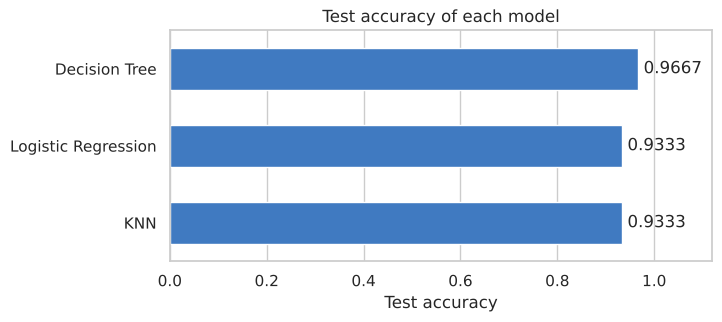

In [17]:
plt.figure(figsize=(7, 3))
ax = sns.barplot(data=results, x="Test accuracy", y="Model", color="#2a78d6", width=0.55)
ax.bar_label(ax.containers[0], fmt="%.4f", padding=4)
plt.xlim(0, 1.12)
plt.ylabel("")
plt.title("Test accuracy of each model")
plt.show()

### Feature importance from the Decision Tree

In [18]:
importance = pd.Series(models["Decision Tree"].feature_importances_, index=features)
importance.sort_values(ascending=False).round(3)

petal length (cm)    0.579
petal width (cm)     0.421
sepal width (cm)     0.000
sepal length (cm)    0.000
dtype: float64

The Decision Tree makes all of its decisions using only petal length and petal width. This matches the feature selection discussion in Section 5: the petal features are the most discriminative.

## 10. Best-performing model

In [19]:
# The first row of the results table has the highest test accuracy
best_name = results.loc[0, "Model"]

print("Best-performing model:", best_name)
print("Test accuracy        :", round(results.loc[0, "Test accuracy"], 4))
print("Train accuracy       :", round(results.loc[0, "Train accuracy"], 4))

Best-performing model: Decision Tree
Test accuracy        : 0.9667
Train accuracy       : 0.9833


### Best model: Decision Tree

**Justification**

1. **Highest test accuracy (96.67%).** It predicted 29 of the 30 test flowers correctly. Logistic Regression and KNN both predicted 28 of 30 correctly (93.33%).
2. **No serious overfitting.** Its train accuracy is 98.33% and its test accuracy is 96.67%, so the gap is small.
3. **Only one mistake.** One Versicolor flower was predicted as Virginica. Every Setosa and every Virginica flower was predicted correctly.
4. **Easy to understand.** A Decision Tree is a set of simple if/else rules, and it uses only petal length and petal width, which are the most discriminative features.

**Note:** the three models are very close. The Decision Tree is ahead by only one flower, and the test set has only 30 flowers, so with a different train/test split the ranking could change.

### Predicting a new flower with the best model

In [20]:
# sepal length, sepal width, petal length, petal width (in cm)
new_flower = pd.DataFrame([[5.9, 3.0, 4.2, 1.5]], columns=features)

new_flower_scaled = scaler.transform(new_flower)
print("Predicted species:", models[best_name].predict(new_flower_scaled)[0])

Predicted species: versicolor


## 11. Conclusion

- The Iris dataset has 150 flowers, 4 features and 3 balanced species, with no missing values.
- Petal length and petal width are the most discriminative features. Setosa is easy to separate; Versicolor and Virginica overlap slightly.
- Three models were trained on an 80/20 split: Logistic Regression, KNN and Decision Tree.
- All three models gave more than 93% accuracy on the test set. Setosa was classified correctly by every model.
- **The Decision Tree is selected as the best-performing model**, with 96.67% test accuracy (29 of 30 flowers correct).

**Future improvements:** try different values of `k` for KNN, and test the models on a larger dataset.